In [1]:
import eu9_osm_fast
from eu9_osm_fast import local_osm_features
import json
import geopandas as gpd
import pandas as pd
import mapclassify
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

In [2]:
# Data
tags = {"amenity": ["cafe", "bar"]}

points = local_osm_features("points", tags=tags, region="mainland")
lines = local_osm_features("lines", tags=tags, region="mainland")
areas = local_osm_features("areas", tags=tags, region="mainland")

# Concat 3 layers
cafes_bars = gpd.GeoDataFrame(pd.concat([points, lines, areas], ignore_index=True), crs=points.crs)

In [3]:
# Amenity classification
cafes_bars["amenity"] = cafes_bars["tags_json"].apply(lambda x: json.loads(x).get("amenity"))

In [4]:
# Remove duplicates
cafes_bars = cafes_bars.drop_duplicates(subset=["osm_type", "osm_id"]).copy()

In [5]:
# Separate data
cafes = cafes_bars[cafes_bars["amenity"] == "cafe"]
bars = cafes_bars[cafes_bars["amenity"] == "bar"]

In [6]:
# Population data
pop = gpd.read_file("portugal-municipal-population-age-2025.887ffbec2267.geojson")
pop = pop[pop["region"] == "Continente"].reset_index()

In [7]:
# Reprojection
cafes = cafes.to_crs(pop.crs)
bars = bars.to_crs(pop.crs)

In [8]:
# Convert polies to representative point
cafes["geometry"] = cafes.geometry.representative_point()
bars["geometry"] = bars.geometry.representative_point()

In [9]:
# Count cafes and bars by municipality
def count_pois(pois, municipalities):
    joined = gpd.sjoin(pois, municipalities[["municipality_code", "geometry"]], how="inner", predicate="within")
    return joined.groupby("municipality_code").size()

In [10]:
# Counts
pop["cafes"] = (pop["municipality_code"].map(count_pois(cafes, pop)).fillna(0))
pop["bars"] = (pop["municipality_code"].map(count_pois(bars, pop)).fillna(0))

In [11]:
# Density per 10000 people
pop["cafes_10k"] = (pop["cafes"] / pop["population"] * 10000)
pop["bars_10k"] = (pop["bars"] / pop["population"] * 10000)

In [12]:
# Relevant columns
gdf = pop.copy()
gdf = gdf[["name", "municipality_code", "population", "cafes", "bars", "cafes_10k", "bars_10k", "geometry"]]

In [13]:
# Classification
gdf["x_group"] = gdf[["cafes_10k"]].apply(mapclassify.Quantiles.make(rolling=True, k = 3))
gdf["y_group"] = gdf[["bars_10k"]].apply(mapclassify.Quantiles.make(rolling=True, k = 3))
gdf["xy_group"] = gdf["x_group"].astype(str) + gdf["y_group"].astype(str)

In [14]:
color_mapping = {
    "00": "#F3E9D2",
    "01": "#B8D8D3",
    "02": "#78B8B0",
    "10": "#E5B5A2",
    "11": "#B5B6A6",
    "12": "#6FA6A5",
    "20": "#D17A68",
    "21": "#A77E83",
    "22": "#665B78"
}

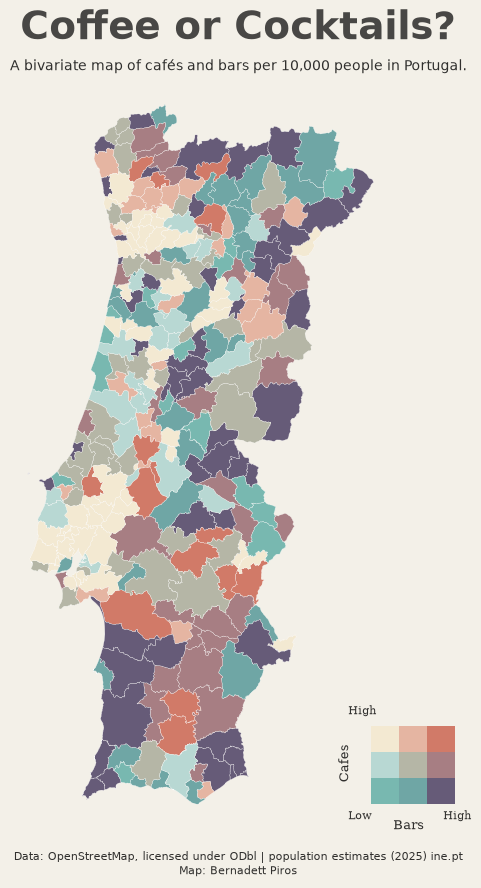

In [15]:
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#F3F0E8")

gdf.plot(color=gdf["xy_group"].map(color_mapping).fillna("#808080"),
         ec="white", lw=0.2, ax=ax)

# Legend
legend_elements = []
for key, value in color_mapping.items():
    legend_elements.append(Patch(facecolor=value, edgecolor=None))
ax.legend(
    handles=legend_elements, 
    loc="lower right",  
    bbox_to_anchor=(1.2, 0.03),
    ncol=3, 
    frameon=False,
    handletextpad=0, 
    labelspacing = 0, 
    columnspacing = 0,
    handlelength=2,
    handleheight=2.5,    
)

ax.set_facecolor("#F3F0E8")
ax.axis("off")

fig.text(0.66, 0.235, "High", color="black", alpha=0.8, size=8, fontfamily="DejaVu Serif")
fig.text(0.66, 0.13, "Low", color="black", alpha=0.8, size=8, fontfamily="DejaVu Serif")
fig.text(0.755, 0.13, "High", color="black", alpha=0.8, size=8, fontfamily="DejaVu Serif")

fig.text(0.65, 0.17, "Cafes", color="black", alpha=0.8, size=9, rotation=90, fontfamily="DejaVu Serif")
fig.text(0.705, 0.12, "Bars", color="black", alpha=0.8, size=9, fontfamily="DejaVu Serif")

fig.text(0.55, 0.94,
         "Coffee or Cocktails?",
         color="black", alpha=0.7, size=28, weight="bold", ha="center", va="top")

fig.text(0.55, 0.89,
         "A bivariate map of cafés and bars per 10,000 people in Portugal.",         
         color="black", alpha=0.8, ha="center", va="top")

fig.text(0.55, 0.075,
         "Data: OpenStreetMap, licensed under ODbl | population estimates (2025) ine.pt\n"
         "Map: Bernadett Piros",  
         color="black", alpha=0.8, size=8, ha="center")

#plt.show()

fig.savefig("cafes_bars.png", bbox_inches="tight", pad_inches=0.2) 